# **Support Vector Machine**

# Import Library

In [ ]:
import numpy as np
import pandas as pd

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder, OneHotEncoder

#for MODEL
from sklearn.svm import SVC

#for checking testing results
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, confusion_matrix


# Input Data

In [ ]:
df = pd.read_excel('/content/Dataset banjir.xlsx')
df.head()

,Tanggal Banjir,Rata-Rata Suhu Udara (˚C),Rata-Rata Kelembapan (%),Rata-Rata Angin Permukaan (˚),Musim - Angin Monsun (˚),Jumlah Curah Hujan (mm),Total Curah Hujan 1 Minggu (mm),"Terjadi Banjir (1=Ya, 0=Tidak)"
0,19 Juni 2010,27.5,85.0,160,130,74,41,1
1,21 Juli 2010,26.2,90.0,130,130,89,63,1
2,24 November 2010,26.0,90.0,200,330,15,1,0
3,3 Desember 2010,25.8,90.0,360,330,166,12,1
4,15 Februari 2011,25.7,87.0,330,330,18,27,1


# Melakukan Drop Data Yang Tidak Diperlukan


In [ ]:
df=df.drop(columns=['Tanggal Banjir'])

In [ ]:
df.head()

,Rata-Rata Suhu Udara (˚C),Rata-Rata Kelembapan (%),Rata-Rata Angin Permukaan (˚),Musim - Angin Monsun (˚),Jumlah Curah Hujan (mm),Total Curah Hujan 1 Minggu (mm),"Terjadi Banjir (1=Ya, 0=Tidak)"
0,27.5,85.0,160,130,74,41,1
1,26.2,90.0,130,130,89,63,1
2,26.0,90.0,200,330,15,1,0
3,25.8,90.0,360,330,166,12,1
4,25.7,87.0,330,330,18,27,1


# Check Missing Value

In [ ]:
df.isnull().sum()

,0
Rata-Rata Suhu Udara (˚C),0
Rata-Rata Kelembapan (%),0
Rata-Rata Angin Permukaan (˚),0
Musim - Angin Monsun (˚),0
Jumlah Curah Hujan (mm),0
Total Curah Hujan 1 Minggu (mm),0
"Terjadi Banjir (1=Ya, 0=Tidak)",0


# Information of dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Rata-Rata Suhu Udara (˚C)        50 non-null     float64
 1   Rata-Rata Kelembapan (%)         50 non-null     float64
 2   Rata-Rata Angin Permukaan (˚)    50 non-null     int64  
 3   Musim - Angin Monsun (˚)         50 non-null     int64  
 4   Jumlah Curah Hujan (mm)          50 non-null     int64  
 5   Total Curah Hujan 1 Minggu (mm)  50 non-null     int64  
 6   Terjadi Banjir (1=Ya, 0=Tidak)   50 non-null     int64  
dtypes: float64(2), int64(5)
memory usage: 2.9 KB


### Handling Missing value Categorical dataset

In [ ]:
# Menggunakan tanda kurung siku dan string
df['Terjadi Banjir (1=Ya, 0=Tidak)'].value_counts()

,count
"Terjadi Banjir (1=Ya, 0=Tidak)",
0,29
1,21


Karena tidak terlalu jauh perbedaan 0 dan 1 jadi tidak perlu diseimbangkan

---



# Train-Test Split

In [ ]:
X = df.drop(columns='Terjadi Banjir (1=Ya, 0=Tidak)')
y = df['Terjadi Banjir (1=Ya, 0=Tidak)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((40, 6), (10, 6), (40,), (10,))

In [ ]:
X_train.columns

Index(['Rata-Rata Suhu Udara (˚C)', 'Rata-Rata Kelembapan (%)',
       'Rata-Rata Angin Permukaan (˚)', 'Musim - Angin Monsun (˚)',
       'Jumlah Curah Hujan (mm)', 'Total Curah Hujan 1 Minggu (mm)'],
      dtype='object')

# Scaling

In [ ]:
columns = ['Rata-Rata Suhu Udara (˚C)', 'Rata-Rata Kelembapan (%)', 'Rata-Rata Angin Permukaan (˚)', 'Musim - Angin Monsun (˚)', 'Jumlah Curah Hujan (mm)',
           'Total Curah Hujan 1 Minggu (mm)']

scaler = StandardScaler()
X_train[columns] = scaler.fit_transform(X_train[columns])
X_test[columns] = scaler.transform(X_test[columns])

# SVM Model

In [ ]:
model = SVC()
model.fit(X_train, y_train)

SVC()

# Evaluate model

In [ ]:
y_pred = model.predict(X_test)
y_pred

array([1, 0, 0, 0, 1, 0, 0, 1, 0, 0])

In [ ]:
print ('accuracy_score: ',accuracy_score(y_test,y_pred))

accuracy_score:  0.8


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86         7
           1       0.67      0.67      0.67         3

    accuracy                           0.80        10
   macro avg       0.76      0.76      0.76        10
weighted avg       0.80      0.80      0.80        10



In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[6, 1],
       [1, 2]])

Text(0.5, 1.0, 'Confusion Matrix Model')

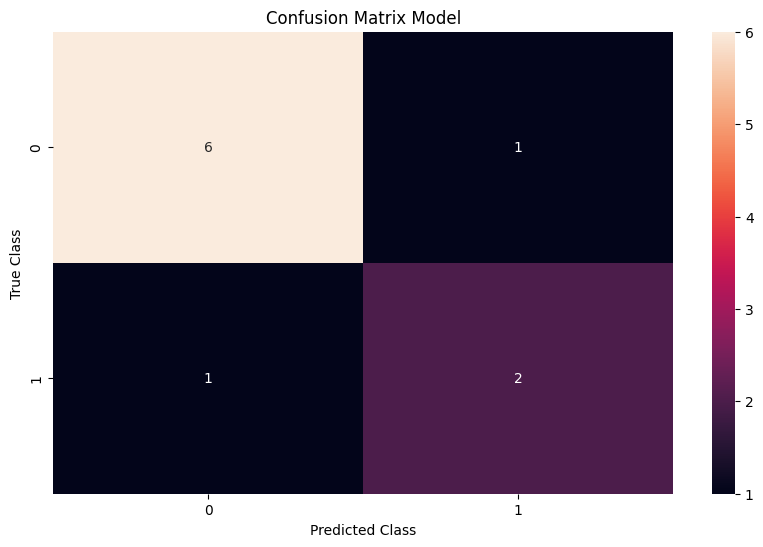

In [ ]:
fig = plt.figure(figsize = (10, 6))
sns.heatmap(cm, annot = True, fmt = "d")

# Labeling the X-axis
plt.xlabel("Predicted Class")

# Labeling the Y-axis
plt.ylabel("True Class")

# Give a title to the graph
plt.title("Confusion Matrix Model")